In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

watch = pd.read_csv('C:\\Users\\PC\Desktop\\project\\data\\WatchHistory.csv')
movies = pd.read_csv('C:\\Users\\PC\\Desktop\\project\\data\\Movies.csv')
users = pd.read_csv('C:\\Users\\PC\\Desktop\\project\\data\\Users.csv')

print("WatchHistory shape:", watch.shape)
print(watch.head(3))
print(watch.info())
print("\nMovies shape:", movies.shape)
print(movies.head(3))
print(movies.info())
print("\nUsers shape:", users.shape)
print(users.head(3))
print(users.info())

WatchHistory shape: (15, 5)
  watch_id user_id movie_id  watch_date watch_duration_mins
0     W001    U001     M001  2026-11-01                  55
1     W002    U001     M004  2026-11-02                  90
2     W003    U002     M003  2026-11-03                  54
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   watch_id             15 non-null     str  
 1   user_id              15 non-null     str  
 2   movie_id             15 non-null     str  
 3   watch_date           15 non-null     str  
 4   watch_duration_mins  15 non-null     str  
dtypes: str(5)
memory usage: 732.0 bytes
None

Movies shape: (12, 5)
  movie_id            title     genre  release_year  duration_mins
0     M001  Stranger Things    Sci-Fi          2016             55
1     M002      The Witcher   Fantasy          2019             60
2     M003       Squid Game  Thrill

<>:6: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:6: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
C:\Users\PC\AppData\Local\Temp\ipykernel_39324\3933187144.py:6: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  watch = pd.read_csv('C:\\Users\\PC\Desktop\\project\\data\\WatchHistory.csv')


In [10]:
print("--- WATCH HISTORY ---")
print(watch.to_string())
print("\n--- MOVIES ---")
print(movies.to_string())
print("\n--- USERS ---")
print(users.to_string())

--- WATCH HISTORY ---
   watch_id user_id movie_id  watch_date watch_duration_mins
0      W001    U001     M001  2026-11-01                  55
1      W002    U001     M004  2026-11-02                  90
2      W003    U002     M003  2026-11-03                  54
3      W004    U003     M005  2026-11-04                  45
4      W005    U004     M001  2026-11-05                  55
5      W006    U004     M007  2026-11-06                 139
6      W007    U005     M002  2026-11-07                  30
7      W008    U006     M008  2026-11-08                  50
8      W009    U007     M009  2026-11-09                  48
9      W010    U008     M006  2026-11-10                  52
10     W011    U009     M010  2026-11-11                 100
11     W012    U010     M011  2026-11-12                 148
12     W013    U002     M001  2026-11-13                  55
13     W014    U009     M003  2026-11-14             invalid
14     W001    U001     M001  2026-11-01                  55

-

In [11]:

# Clean datasets
watch_clean = watch.drop_duplicates().copy()
movies_clean = movies.drop_duplicates().copy()
users_clean = users.drop_duplicates().copy()

# Convert watch_duration_mins to numeric
watch_clean['watch_duration_numeric'] = pd.to_numeric(watch_clean['watch_duration_mins'], errors='coerce')

# Merge datasets
df = watch_clean.merge(movies_clean, on='movie_id', how='left').merge(users_clean, on='user_id', how='left')
df['completion_rate'] = (df['watch_duration_numeric'] / df['duration_mins']) * 100

print("Cleaned merged data:")
print(df[['watch_id', 'user_id', 'country', 'subscription_plan', 'movie_id', 'title', 'genre', 'release_year', 'duration_mins', 'watch_duration_numeric', 'completion_rate']].to_string())

# Aggregate by movie
movie_stats = df.groupby(['movie_id', 'title', 'genre', 'release_year', 'duration_mins'], dropna=False).agg(
    watch_count=('watch_id', 'count'),
    unique_users=('user_id', 'nunique'),
    valid_watch_mins=('watch_duration_numeric', 'sum'),
    avg_completion=('completion_rate', 'mean'),
    countries=('country', lambda x: ', '.join(sorted(set(x)))),
    plans=('subscription_plan', lambda x: ', '.join(sorted(set(x))))
).reset_index().sort_values(by=['watch_count', 'avg_completion'], ascending=[False, False])

print("\nMovie Popularity Stats:")
print(movie_stats.to_string())

# Aggregate by genre
genre_stats = df.groupby('genre', dropna=False).agg(
    total_watches=('watch_id', 'count'),
    unique_titles=('movie_id', 'nunique'),
    avg_completion=('completion_rate', 'mean'),
    total_valid_mins=('watch_duration_numeric', 'sum')
).reset_index().sort_values(by='total_watches', ascending=False)

print("\nGenre Stats:")
print(genre_stats.to_string())

# Short vs Long format (< 70 mins vs > 70 mins)
df['format'] = np.where(df['duration_mins'] <= 60, 'Series/Short (<=60m)', 'Feature Film (>60m)')
format_stats = df.groupby('format').agg(
    total_watches=('watch_id', 'count'),
    unique_titles=('movie_id', 'nunique'),
    avg_completion=('completion_rate', 'mean')
).reset_index()

print("\nFormat Stats:")
print(format_stats.to_string())

Cleaned merged data:
   watch_id user_id country subscription_plan movie_id                           title        genre  release_year  duration_mins  watch_duration_numeric  completion_rate
0      W001    U001   Kenya           Premium     M001                 Stranger Things       Sci-Fi          2016             55                    55.0       100.000000
1      W002    U001   Kenya           Premium     M004                      Extraction       Action          2020            116                    90.0        77.586207
2      W003    U002  Canada          Standard     M003                      Squid Game     Thriller          2021             54                    54.0       100.000000
3      W004    U003   Spain             Basic     M005              The Queen's Gambit        Drama          2020             60                    45.0        75.000000
4      W005    U004   Kenya           Premium     M001                 Stranger Things       Sci-Fi          2016             55 

Chart saved.


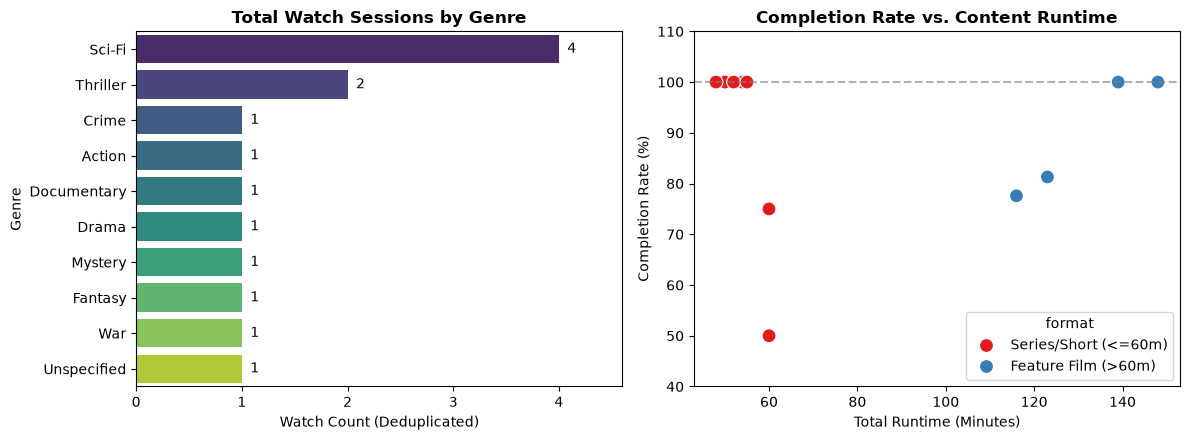

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot 1: Watches by Genre
genre_plot = genre_stats.copy()
genre_plot['genre'] = genre_plot['genre'].fillna('Unspecified')
sns.barplot(data=genre_plot, x='total_watches', y='genre', ax=axes[0], palette='viridis', hue='genre', legend=False)
axes[0].set_title('Total Watch Sessions by Genre', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Watch Count (Deduplicated)')
axes[0].set_ylabel('Genre')
for i, v in enumerate(genre_plot['total_watches']):
    axes[0].text(v + 0.08, i, str(v), va='center')
axes[0].set_xlim(0, 4.6)

# Plot 2: Completion Rate by Runtime
valid_df = df.dropna(subset=['completion_rate']).copy()
sns.scatterplot(data=valid_df, x='duration_mins', y='completion_rate', hue='format', s=100, ax=axes[1], palette='Set1')
axes[1].axhline(100, color='gray', linestyle='--', alpha=0.6)
axes[1].set_title('Completion Rate vs. Content Runtime', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Total Runtime (Minutes)')
axes[1].set_ylabel('Completion Rate (%)')
axes[1].set_ylim(40, 110)

plt.tight_layout()
plt.savefig('content_popularity.png', dpi=150)
print("Chart saved.")

C:\Users\PC\AppData\Local\Temp\ipykernel_39324\2791441728.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=genre_plot, x='total_watches', y='genre', ax=axes[0], palette='viridis')


Chart saved successfully.


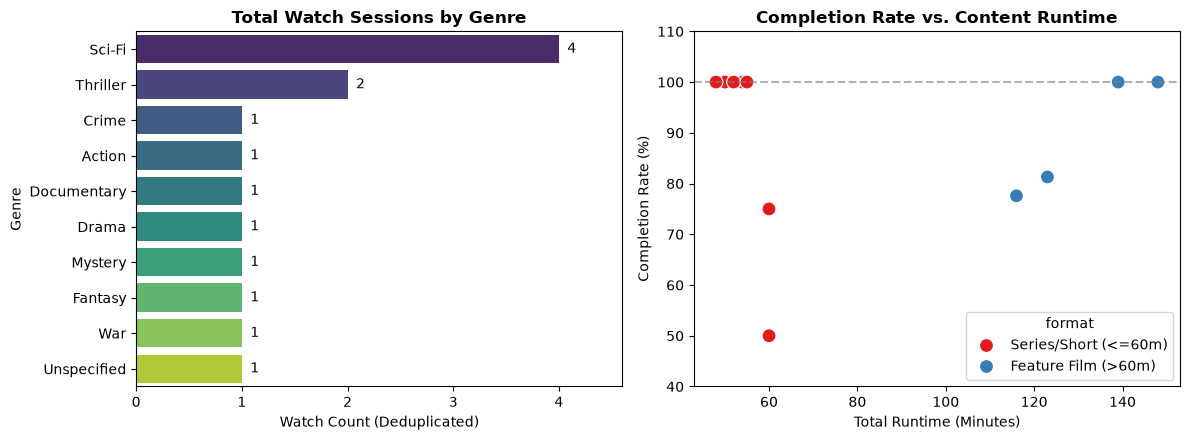

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

genre_plot = genre_stats.copy()
genre_plot['genre'] = genre_plot['genre'].fillna('Unspecified')
sns.barplot(data=genre_plot, x='total_watches', y='genre', ax=axes[0], palette='viridis')
axes[0].set_title('Total Watch Sessions by Genre', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Watch Count (Deduplicated)')
axes[0].set_ylabel('Genre')
for i, v in enumerate(genre_plot['total_watches']):
    axes[0].text(v + 0.08, i, str(v), va='center')
axes[0].set_xlim(0, 4.6)

valid_df = df.dropna(subset=['completion_rate']).copy()
sns.scatterplot(data=valid_df, x='duration_mins', y='completion_rate', hue='format', s=100, ax=axes[1], palette='Set1')
axes[1].axhline(100, color='gray', linestyle='--', alpha=0.6)
axes[1].set_title('Completion Rate vs. Content Runtime', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Total Runtime (Minutes)')
axes[1].set_ylabel('Completion Rate (%)')
axes[1].set_ylim(40, 110)

plt.tight_layout()
plt.savefig('content_popularity.png', dpi=150)
print("Chart saved successfully.")